# Phase 3 - final ESP32-S3 people counter (one run, top to bottom)

Reads the Phase 1 output in `D:/wifi/shared_format` and the raw WiCount CSVs. **Run Phase 1 first.**
All the counting code is in `D:/wifi/esp32_counter/esp32_counter.py`; this notebook only drives it.

**What is different from Phase 2 (so the numbers match what the device will do)**

| Phase 2 | Phase 3 (device-ready) |
|---|---|
| each tone divided by its mean over the **whole recording** (uses the future) | **causal** baseline per tone (30 s EMA), first 10 s skipped |
| calibration from **all** windows of the test setup | **20 s empty-room calibration** at install, or none |
| 16 views averaged | **one view** = one ESP32 link |
| per-window estimate | per-window + **30 s rolling median** (what the display shows) |
| GBM + CNN | GBM regression only (best on one link in Phase 2, ~10x smaller than the classifier) |

**Experiments** (every test group is unseen in training; `empty_cal` = 20 s empty-room offset)

| Id | Train | Test | Question |
|---|---|---|---|
| E1 | 80 MHz set, 3 setups | 4th setup | how good is one link on unseen rooms? |
| E2 | WiCount (ESP32-S3), 14 files | 15th file | ESP32-only model |
| E3 | 80 MHz set | WiCount | does a router-trained model work on ESP32 hardware? |
| E4 | 80 MHz set + 14 WiCount files | 15th file | does the 80 MHz data help the ESP32? |
| E5 | 80 MHz set | CountFi | stress test only (time-confounded labels) |

**Final model:** the candidate with the lowest smoothed MAE on WiCount (E2/E3/E4); within 0.05 the one
with more training data and no install step wins. It is retrained on all its data and exported:

```
D:/wifi/results/phase3_esp32_final__mat80_wicount_countfi/model_esp32_counter/
    trees.json        model for Python (no LightGBM needed)
    counter_model.h   same model for the ESP32 firmware (C arrays + cc_prepare + cc_predict)
    model.txt         LightGBM native file
    model_card.json   settings, calibration, held-out results, caveats
```

**Needs:** `numpy pandas pyarrow scipy matplotlib lightgbm tabulate` (no GPU). gcc/clang on PATH is optional
(one test compiles the C header). Results go to `D:/wifi/results/phase3_esp32_final__mat80_wicount_countfi/`.

In [1]:
# 1. Paths, settings, load the counter code
import glob
import importlib
import json
import os
import sys
import time
import unittest

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

WIFI_ROOT = "D:/wifi"
CODE_DIR = f"{WIFI_ROOT}/esp32_counter"            # esp32_counter.py + tests
RAW = f"{WIFI_ROOT}/Datasets"                      # raw WiCount CSVs (replay check)
SHARED = f"{WIFI_ROOT}/shared_format"              # Phase 1 output
RESULTS = f"{WIFI_ROOT}/results/phase3_esp32_final__mat80_wicount_countfi"
MODEL_DIR = f"{WIFI_ROOT}/results/phase3_esp32_final__mat80_wicount_countfi/model_esp32_counter"     # final model bundle
os.makedirs(RESULTS, exist_ok=True)

sys.path.insert(0, CODE_DIR)
import esp32_counter as ec
importlib.reload(ec)

FEATURES = ec.FEATURE_NAMES
DATASETS = ["mat80", "wicount", "countfi"]
MODES = ["zero_shot", "empty_cal"]
SEED = 0

GBM_PARAMS = dict(objective="regression", n_estimators=300, learning_rate=0.05, num_leaves=15,
                  min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                  random_state=SEED, verbose=-1)

print(json.dumps(ec.settings_dict(), indent=1))

{
 "fs_hz": 50,
 "win_s": 5.0,
 "hop_s": 2.5,
 "n_tones": 52,
 "max_gap_bins": 3,
 "max_missing": 0.2,
 "tau_s": 30.0,
 "warmup_s": 10.0,
 "cal_s": 20.0,
 "n_cal_windows": 7,
 "smooth_s": 30.0,
 "smooth_n": 12,
 "feature_names": [
  "cv_median",
  "cv_p90",
  "cv_p10",
  "diff_energy",
  "pc1_frac",
  "n_pc_90",
  "tone_corr",
  "low_freq_frac",
  "high_freq_frac",
  "mean_std"
 ],
 "log_features": [
  "cv_median",
  "cv_p90",
  "cv_p10",
  "diff_energy",
  "mean_std"
 ]
}


In [2]:
# 2. Unit tests - the run stops here if anything fails
import test_esp32_counter as tests
importlib.reload(tests)

suite = unittest.defaultTestLoader.loadTestsFromModule(tests)
result = unittest.TextTestRunner(verbosity=2, stream=sys.stdout).run(suite)

if not result.wasSuccessful():
    raise RuntimeError("Unit tests failed - fix esp32_counter.py before training.")
print(f"all tests passed ({len(result.skipped)} skipped)")

test_calibration_offset_centres_features (test_esp32_counter.TestCounter.test_calibration_offset_centres_features) ... ok
test_prepare_handles_nan (test_esp32_counter.TestCounter.test_prepare_handles_nan) ... ok
test_smoothing_is_causal_median (test_esp32_counter.TestCounter.test_smoothing_is_causal_median) ... ok
test_streaming_counter_end_to_end (test_esp32_counter.TestCounter.test_streaming_counter_end_to_end) ... ok
test_bundle_roundtrip (test_esp32_counter.TestModel.test_bundle_roundtrip) ... ok
test_c_header_matches_python (test_esp32_counter.TestModel.test_c_header_matches_python)
Compile the generated header with gcc/clang (skipped if no C compiler). ... ok
test_flash_budget (test_esp32_counter.TestModel.test_flash_budget) ... ok
test_json_roundtrip (test_esp32_counter.TestModel.test_json_roundtrip) ... ok
test_tree_export_matches_lightgbm (test_esp32_counter.TestModel.test_tree_export_matches_lightgbm) ... ok
test_features_match_phase1_on_real_data (test_esp32_counter.TestPrep

In [3]:
# 3. Data checks: Phase 1 settings, recordings per site, real ESP32 packet rate

# ---- Phase 1 must use the same grid as the counter ----
fmt = json.load(open(os.path.join(SHARED, "format.json")))
for key in ["fs_hz", "win_s", "hop_s", "n_tones", "max_gap_bins", "max_missing"]:
    if fmt[key] != ec.settings_dict()[key]:
        raise ValueError(f"format.json {key}={fmt[key]} differs from esp32_counter.py")

# ---- recordings per site (metadata only) ----
meta_rows = []
for ds in DATASETS:
    for path in sorted(glob.glob(os.path.join(SHARED, ds, "*.npz"))):
        with np.load(path) as z:
            meta = json.loads(str(z["meta"]))
            n_views = len(z["view_names"])
        meta_rows.append({**meta, "views": n_views, "path": path})

recs = pd.DataFrame(meta_rows)
if recs.empty:
    raise FileNotFoundError(f"No recordings in {SHARED}. Run phase1_shared_format_local.ipynb first.")

sites = (recs.groupby(["dataset", "setup"])
         .agg(recordings=("recording", "size"),
              counts=("count", lambda c: sorted(set(c))),
              has_empty=("count", lambda c: bool((c == 0).any())),
              minutes=("seconds", lambda s: round(s.sum() / 60, 1)),
              missing=("missing_frac", "mean")))
display(sites)


# ---- raw ESP32-S3 packets (WiCount) ----
WRAP = 2 ** 32                                       # local_timestamp is a 32-bit microsecond counter


def read_wicount_csv(path):
    """Raw ESP32-S3 packets: times (s) and amplitude (packets, 52), time-ordered."""
    df = pd.read_csv(path)
    rows, keep_t = [], []
    for ts, txt in zip(df["local_timestamp"], df["data"]):
        try:
            vals = json.loads(txt)
        except (TypeError, ValueError):
            continue
        if len(vals) == 2 * ec.N_TONES:
            rows.append(vals)
            keep_t.append(ts)

    iq = np.array(rows, dtype=np.float32)
    A = np.hypot(iq[:, 0::2], iq[:, 1::2])

    dt = np.diff(np.array(keep_t, dtype=np.int64))
    dt[dt < 0] += WRAP
    t = np.concatenate([[0], np.cumsum(dt)]) * 1e-6
    order = np.argsort(t, kind="stable")
    return t[order], A[order]


WICOUNT_CSVS = sorted(glob.glob(os.path.join(RAW, "WiCount", "data", "*", "*.csv")))
rate_rows = []
for path in WICOUNT_CSVS:
    t, A = read_wicount_csv(path)
    dt_ms = np.diff(t) * 1000
    bins = np.unique(np.floor(t * ec.FS).astype(int))
    rate_rows.append({"file": os.path.basename(path), "count": int(os.path.basename(os.path.dirname(path))),
                      "packets": len(t), "seconds": round(t[-1], 1),
                      "rate_hz": round(len(t) / max(t[-1], 1e-9), 1),
                      "dt_median_ms": round(float(np.median(dt_ms)), 1),
                      "dt_p99_ms": round(float(np.percentile(dt_ms, 99)), 1),
                      "bins_with_data": round(len(bins) / (int(t[-1] * ec.FS) + 1), 3)})
rate = pd.DataFrame(rate_rows)
display(rate)

slow = rate[rate["rate_hz"] < ec.FS]
if len(slow):
    print(f"WARNING: {len(slow)} WiCount files send fewer than {ec.FS} packets/s - "
          "set the ESP32 traffic to >= 100 packets/s for your own recordings.")
print(f"median ESP32 packet rate: {rate['rate_hz'].median():.0f} Hz, "
      f"bins with data: {rate['bins_with_data'].median():.1%}")

recordings                           counts  has_empty  \
dataset setup                                                           
countfi fm             12              [1, 3, 4, 5, 8, 10]      False   
        mm             18     [1, 2, 3, 4, 5, 6, 7, 8, 10]      False   
        mm_v2          12              [1, 3, 4, 5, 8, 10]      False   
        mm_v3          16        [1, 3, 4, 5, 6, 7, 8, 10]      False   
        ms              6                        [1, 5, 8]      False   
        rm             12              [1, 3, 4, 5, 8, 10]      False   
mat80   PC1a           10  [0, 2, 3, 4, 5, 6, 7, 8, 9, 10]       True   
        PC2a            9     [2, 3, 4, 5, 6, 7, 8, 9, 10]      False   
        PC3a           10  [0, 2, 3, 4, 5, 6, 7, 8, 9, 10]       True   
        PC4a           10  [0, 2, 3, 4, 5, 6, 7, 8, 9, 10]       True   
wicount room           15                     [0, 1, 2, 3]       True   

               minutes   missing  
dataset setup                     
countfi fm        12.6  0.018692  
        mm        28.0  0.021594  
        mm_v2     14.6  0.011508  
        mm_v3     14.0  0.017150  
        ms         3.2  0.042500  
        rm         9.8  0.017325  
mat80   PC1a      45.0  0.000000  
        PC2a      39.3  0.000000  
        PC3a      45.4  0.000000  
        PC4a      45.2  0.000000  
wicount room      15.0  0.002313

,file,count,packets,seconds,rate_hz,dt_median_ms,dt_p99_ms,bins_with_data
0,2023-12-21_19-23-53-985_104_1.csv,0,5218,60.0,87.0,12.0,20.4,0.995
1,2023-12-21_19-27-21-930_104_1.csv,1,4780,60.0,79.7,12.0,32.8,0.970
2,2023-12-21_19-31-17-706_104_1.csv,1,5189,60.0,86.5,12.0,20.3,0.998
3,2023-12-21_19-34-42-783_104_1.csv,1,5234,60.0,87.2,12.0,20.3,0.999
4,2023-12-21_19-37-36-861_104_1.csv,1,5163,60.0,86.1,12.0,20.5,0.997
5,2023-12-21_19-40-12-110_104_1.csv,1,5421,60.0,90.4,12.0,20.0,0.999
6,2023-12-21_19-42-28-267_104_1.csv,1,5644,60.0,94.1,12.0,19.7,1.000
7,2023-12-21_19-45-07-501_104_1.csv,1,5128,60.0,85.5,12.0,21.8,0.995
8,2023-12-21_19-47-14-669_104_1.csv,2,5376,60.0,89.6,12.0,20.0,0.998
9,2023-12-21_19-49-37-940_104_1.csv,2,5307,60.0,88.5,12.0,20.0,1.000


median ESP32 packet rate: 87 Hz, bins with data: 99.8%


In [4]:
# 4. Causal features for every recording and view (cached)
CACHE = os.path.join(SHARED, "causal_features.parquet")
CACHE_KEY = os.path.join(SHARED, "causal_features.json")

cache_ok = (os.path.exists(CACHE) and os.path.exists(CACHE_KEY)
            and json.load(open(CACHE_KEY)) == ec.settings_dict())

if cache_ok:
    cf = pd.read_parquet(CACHE)
    print("loaded cached causal features:", len(cf), "rows")
else:
    rows = []
    t0 = time.time()
    for i, r in enumerate(recs.to_dict("records")):
        with np.load(r["path"]) as z:
            S, valid = z["series"], z["valid"]
            views = [str(v) for v in z["view_names"]]

        for v, view in enumerate(views):
            # Phase 1 stored x / recording_mean - 1; the mean cancels in the causal baseline
            X = S[v].astype(np.float32) + 1.0
            starts, F = ec.features_from_series(X, valid)
            for j, a in enumerate(starts):
                rows.append({"dataset": r["dataset"], "recording": r["recording"], "setup": r["setup"],
                             "count": r["count"], "view": view, "window": j, "t_start_s": a / ec.FS,
                             **dict(zip(FEATURES, F[j]))})

        if (i + 1) % 20 == 0 or i + 1 == len(recs):
            print(f"{i + 1:4d}/{len(recs)} recordings  [{time.time() - t0:.0f} s]")

    cf = pd.DataFrame(rows)
    cf.to_parquet(CACHE, index=False)
    json.dump(ec.settings_dict(), open(CACHE_KEY, "w"))

# ---- empty-room calibration windows: first 20 s after warm-up of each site's empty recording ----
empty_rec = (recs[recs["count"] == 0].sort_values("recording")
             .groupby(["dataset", "setup"])["recording"].first())

cf["is_cal"] = False
for (ds, setup), rec in empty_rec.items():
    m = ((cf["dataset"] == ds) & (cf["recording"] == rec)
         & (cf["t_start_s"] + ec.WIN_S <= ec.WARMUP_S + ec.CAL_S + 1e-9))
    cf.loc[m, "is_cal"] = True

OFFSETS = {key: ec.calibration_offset(g[FEATURES].values)
           for key, g in cf[cf["is_cal"]].groupby(["dataset", "setup", "view"])}
EMPTY_SITES = {(ds, setup) for ds, setup, _ in OFFSETS}

# calibration windows are never used for training or scoring
DATA = cf[~cf["is_cal"]].reset_index(drop=True)

print("empty recording per site:", dict(empty_rec))
print("sites without an empty recording (no empty_cal):",
      sorted(set(zip(recs["dataset"], recs["setup"])) - EMPTY_SITES))
DATA.groupby("dataset").agg(recordings=("recording", "nunique"), views=("view", "nunique"),
                            windows=("window", "size"))

  20/130 recordings  [117 s]
  40/130 recordings  [278 s]
  60/130 recordings  [285 s]
  80/130 recordings  [299 s]
 100/130 recordings  [313 s]
 120/130 recordings  [324 s]
 130/130 recordings  [328 s]
empty recording per site: {('mat80', 'PC1a'): 'PC1a_n00', ('mat80', 'PC3a'): 'PC3a_n00', ('mat80', 'PC4a'): 'PC4a_n00', ('wicount', 'room'): '2023-12-21_19-23-53-985_104_1'}
sites without an empty recording (no empty_cal): [('countfi', 'fm'), ('countfi', 'mm'), ('countfi', 'mm_v2'), ('countfi', 'mm_v3'), ('countfi', 'ms'), ('countfi', 'rm'), ('mat80', 'PC2a')]


,recordings,views,windows
dataset,,,
countfi,70,4,6200
mat80,39,16,63440
wicount,15,1,274


In [5]:
# 5. Train / predict / score helpers
PRED_PARTS = []


def model_inputs(df, mode):
    """Model input + mask of usable rows (empty_cal needs an offset for the row's site + view)."""
    df = df.reset_index(drop=True)
    F = df[FEATURES].values
    if mode == "zero_shot":
        return ec.prepare_features(F), np.ones(len(df), dtype=bool)

    X = np.zeros((len(df), len(FEATURES)), dtype=np.float32)
    ok = np.zeros(len(df), dtype=bool)
    for key, idx in df.groupby(["dataset", "setup", "view"]).indices.items():
        if key in OFFSETS:
            X[idx] = ec.prepare_features(F[idx], OFFSETS[key])
            ok[idx] = True
    return X, ok


def fit(train_df, mode):
    """LightGBM regression; every dataset in the training set gets the same total weight."""
    X, ok = model_inputs(train_df, mode)
    d = train_df.reset_index(drop=True)[ok]
    w = 1.0 / d.groupby("dataset")["dataset"].transform("size").values
    reg = lgb.LGBMRegressor(**GBM_PARAMS).fit(X[ok], d["count"].values, sample_weight=w / w.mean())
    return reg, int(d["count"].max())


def predict(reg, max_count, test_df, mode):
    X, ok = model_inputs(test_df, mode)
    p = np.full(len(test_df), np.nan)
    if ok.any():
        p[ok] = np.clip(reg.predict(X[ok]), 0, max_count)
    return p


def collect(experiment, mode, train_desc, test_df, p):
    """Store window predictions + the causal 30 s rolling median per (recording, view) stream."""
    d = test_df[["dataset", "recording", "setup", "count", "view", "window"]].reset_index(drop=True).copy()
    d["raw"] = p
    d = d[~np.isnan(d["raw"])].sort_values(["recording", "view", "window"])
    if d.empty:
        return                                      # e.g. empty_cal on a site without an empty recording
    d["smoothed"] = d.groupby(["recording", "view"])["raw"].transform(
        lambda s: ec.smooth_predictions(s.values))
    d["experiment"], d["mode"], d["train"] = experiment, mode, train_desc
    PRED_PARTS.append(d)


def score(y, pred):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    rounded = np.rint(pred)
    return {"n": len(y), "mae": float(np.mean(np.abs(pred - y))),
            "exact": float(np.mean(rounded == y)),
            "within1": float(np.mean(np.abs(rounded - y) <= 1))}

In [6]:
# 6. Held-out experiments E1-E5 (one view = one ESP32 link)
mat = DATA[DATA["dataset"] == "mat80"]
wic = DATA[DATA["dataset"] == "wicount"]
cfi = DATA[DATA["dataset"] == "countfi"]
PRED_PARTS.clear()
t0 = time.time()

# ---- E1: 80 MHz set, leave one setup out ----
for mode in MODES:
    for site in sorted(mat["setup"].unique()):
        reg, mc = fit(mat[mat["setup"] != site], mode)
        test = mat[mat["setup"] == site]
        collect("E1_mat80_loso", mode, "mat80 other setups", test, predict(reg, mc, test, mode))
    print(f"E1 {mode:9s} done  [{time.time() - t0:.0f} s]")

# ---- E2: ESP32 only, leave one WiCount recording out ----
# (one site only, so the empty-room offset shifts train and test equally: zero_shot == empty_cal)
for rec in sorted(wic["recording"].unique()):
    reg, mc = fit(wic[wic["recording"] != rec], "zero_shot")
    test = wic[wic["recording"] == rec]
    collect("E2_esp32_only", "zero_shot", "wicount other files", test, predict(reg, mc, test, "zero_shot"))
print(f"E2 done  [{time.time() - t0:.0f} s]")

# ---- E3: router data -> ESP32 hardware;  E5: router data -> CountFi (stress test) ----
for mode in MODES:
    reg, mc = fit(mat, mode)
    collect("E3_mat80_to_esp32", mode, "mat80 all", wic, predict(reg, mc, wic, mode))
    if mode == "zero_shot":
        collect("E5_mat80_to_countfi", mode, "mat80 all", cfi, predict(reg, mc, cfi, mode))
print(f"E3 + E5 done  [{time.time() - t0:.0f} s]")

# ---- E4: router data + other ESP32 files -> left-out ESP32 file ----
for mode in MODES:
    for rec in sorted(wic["recording"].unique()):
        reg, mc = fit(pd.concat([mat, wic[wic["recording"] != rec]]), mode)
        test = wic[wic["recording"] == rec]
        collect("E4_mat80_plus_esp32", mode, "mat80 + wicount other files", test,
                predict(reg, mc, test, mode))
    print(f"E4 {mode:9s} done  [{time.time() - t0:.0f} s]")


# ---- scores: per window ('raw') and after the 30 s median ('smoothed') ----
preds = pd.concat(PRED_PARTS, ignore_index=True)
rows = []
for (exp, mode, test_ds), g in preds.groupby(["experiment", "mode", "dataset"]):
    subsets = {"all": g}
    with_empty = g[[(d, s) in EMPTY_SITES for d, s in zip(g["dataset"], g["setup"])]]
    if 0 < len(with_empty) < len(g):
        subsets["with_empty"] = with_empty                  # same sites as the empty_cal run
    for sites_name, h in subsets.items():
        for level in ["raw", "smoothed"]:
            rows.append({"experiment": exp, "mode": mode, "test": test_ds, "sites": sites_name,
                         "level": level, "train": h["train"].iloc[0], **score(h["count"], h[level])})
results = pd.DataFrame(rows)

# ---- whole-recording estimate (median of the smoothed output) + rank correlation ----
per_rec = (preds.groupby(["experiment", "mode", "dataset", "recording"])
           .agg(count=("count", "first"), pred=("smoothed", "median")).reset_index())
spearman = (per_rec.groupby(["experiment", "mode", "dataset"])
            .apply(lambda h: h["pred"].corr(h["count"], method="spearman"))
            .rename("spearman_rec").reset_index())

table = (results[results["level"] == "smoothed"]
         .merge(spearman.rename(columns={"dataset": "test"}), on=["experiment", "mode", "test"], how="left"))
table[["experiment", "mode", "test", "sites", "train", "n", "mae", "exact", "within1", "spearman_rec"]].round(3)

E1 zero_shot done  [25 s]
E1 empty_cal done  [41 s]
E2 done  [52 s]
E3 + E5 done  [53 s]
E4 zero_shot done  [61 s]
E4 empty_cal done  [68 s]


,experiment,mode,test,sites,train,n,mae,exact,within1,spearman_rec
0,E1_mat80_loso,empty_cal,mat80,all,mat80 other setups,49120,2.853,0.186,0.353,0.438
1,E1_mat80_loso,zero_shot,mat80,all,mat80 other setups,63440,1.740,0.215,0.502,0.915
2,E1_mat80_loso,zero_shot,mat80,with_empty,mat80 other setups,49120,1.639,0.238,0.529,0.915
3,E2_esp32_only,zero_shot,wicount,all,wicount other files,274,0.340,0.818,1.000,0.810
4,E3_mat80_to_esp32,empty_cal,wicount,all,mat80 all,274,1.068,0.124,0.803,0.864
5,E3_mat80_to_esp32,zero_shot,wicount,all,mat80 all,274,0.771,0.365,0.891,0.341
6,E4_mat80_plus_esp32,empty_cal,wicount,all,mat80 + wicount other files,274,0.306,0.807,1.000,0.901
7,E4_mat80_plus_esp32,zero_shot,wicount,all,mat80 + wicount other files,274,0.360,0.704,0.993,0.839
8,E5_mat80_to_countfi,zero_shot,countfi,all,mat80 all,6200,4.648,0.035,0.150,-0.025


In [7]:
# 7. Pick the final model, retrain on all its data, export
CANDIDATES = [                                   # preference order when scores tie
    ("E4_mat80_plus_esp32", "zero_shot"),        # most data, no install step
    ("E4_mat80_plus_esp32", "empty_cal"),
    ("E3_mat80_to_esp32", "zero_shot"),
    ("E3_mat80_to_esp32", "empty_cal"),
    ("E2_esp32_only", "zero_shot"),
]
TIE = 0.05
TRAIN_SETS = {"E4_mat80_plus_esp32": ["mat80", "wicount"],
              "E3_mat80_to_esp32": ["mat80"],
              "E2_esp32_only": ["wicount"]}

esp = (results[(results["test"] == "wicount") & (results["level"] == "smoothed") & (results["sites"] == "all")]
       .set_index(["experiment", "mode"]))
cand = esp.loc[[c for c in CANDIDATES if c in esp.index], ["n", "mae", "exact", "within1"]]
best_mae = cand["mae"].min()
CHOSEN = next(c for c in CANDIDATES if c in cand.index and cand.loc[c, "mae"] <= best_mae + TIE)
exp, mode = CHOSEN
display(cand.round(3))
print("chosen:", CHOSEN)

e3_rho = spearman.query("experiment == 'E3_mat80_to_esp32' and dataset == 'wicount'")["spearman_rec"].max()
if not e3_rho > 0.5:
    print(f"WARNING: router-trained model barely ranks ESP32 recordings (spearman {e3_rho:.2f}) - "
          "the 80 MHz data does not transfer well to ESP32 hardware.")

# ---- final training on everything the chosen candidate uses ----
final_train = DATA[DATA["dataset"].isin(TRAIN_SETS[exp])]
reg, max_count = fit(final_train, mode)
tree = ec.TreeModel.from_lightgbm(reg.booster_, max_count)

# ---- the exported trees must give the LightGBM numbers on the real training inputs ----
X, ok = model_inputs(final_train, mode)
parity = float(np.max(np.abs(tree.predict(X[ok]) - reg.predict(X[ok]))))
print(f"export parity on {ok.sum()} training windows: max |diff| = {parity:.2e}")
if parity > 1e-3:
    raise RuntimeError("exported trees differ from LightGBM")

held_out = results[(results["experiment"] == exp) & (results["mode"] == mode)]
card = {
    "name": "esp32_people_counter",
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "model": "LightGBM regression on 10 window features, exported as flat trees",
    "input": "ESP32-S3 CSI amplitude, 52 tones (HT20 L-LTF data tones), >= 50 packets/s",
    "output": "people count 0-%d, updated every 2.5 s (median of the last 30 s)" % max_count,
    "training_data": TRAIN_SETS[exp],
    "n_training_windows": int(ok.sum()),
    "calibration": mode,
    "calibration_howto": ("Leave the room empty, start the counter, call begin_calibration(); "
                          "the next %d windows (%.0f s after the %.0f s warm-up) set the offset."
                          % (ec.N_CAL_WINDOWS, ec.CAL_S, ec.WARMUP_S)) if mode == "empty_cal"
                         else "none (zero_shot)",
    "gbm_params": GBM_PARAMS,
    "selection": {"rule": f"lowest smoothed MAE on WiCount held-out files; within {TIE} prefer the "
                          "earlier candidate (more data, no install step)",
                  "candidates": json.loads(cand.reset_index().to_json(orient="records")),
                  "chosen": list(CHOSEN)},
    "held_out_results": json.loads(held_out.to_json(orient="records")),
    "export_parity_max_abs": parity,
    "caveats": [
        "The WiCount score of the chosen model is optimistic: the same files were used to choose it.",
        "WiCount = one room, one evening, counts 0-3; counts 0 and 3 have one file each.",
        "No ESP32 data above 3 people; higher counts come from 4-antenna 80 MHz router data only.",
        "80 MHz setup PC2a has no empty recording; PC4a_n00 looked occupied in the audit.",
        "Re-validate on your own ESP32-S3 recordings before trusting the count.",
    ],
}
card = ec.save_bundle(MODEL_DIR, tree, card, reg.booster_)
print(f"saved {MODEL_DIR}: {card['n_trees']} trees, {card['n_nodes']} nodes, "
      f"~{card['flash_bytes_est'] / 1024:.0f} KB flash")

n    mae  exact  within1
experiment          mode                                 
E4_mat80_plus_esp32 zero_shot  274  0.360  0.704    0.993
                    empty_cal  274  0.306  0.807    1.000
E3_mat80_to_esp32   zero_shot  274  0.771  0.365    0.891
                    empty_cal  274  1.068  0.124    0.803
E2_esp32_only       zero_shot  274  0.340  0.818    1.000

chosen: ('E4_mat80_plus_esp32', 'empty_cal')
export parity on 49394 training windows: max |diff| = 1.28e-05
saved D:/wifi/models/esp32_counter: 300 trees, 8700 nodes, ~77 KB flash


In [8]:
# 8. Final run: stream the raw ESP32-S3 CSVs packet by packet through the saved bundle
# Pipeline check (raw CSV -> device code -> count). For E2/E4 models WiCount was in training,
# so this is NOT an accuracy number - it must agree with the batch pipeline.
model, card = ec.load_bundle(MODEL_DIR)
calibrated = card["calibration"] == "empty_cal"
empty_csv = [p for p in WICOUNT_CSVS if os.path.basename(os.path.dirname(p)) == "0"][0]
cal_end_s = ec.WARMUP_S + ec.CAL_S

# ---- install step: 20 s of the empty room ----
offset = None
if calibrated:
    t, A = read_wicount_csv(empty_csv)
    c = ec.StreamingCounter(model)
    c.begin_calibration()
    for ti, ai in zip(t, A):
        c.push(ti, ai)
        if not c.calibrating:
            break
    offset = c.offset
    print("calibrated on", os.path.basename(empty_csv))

# ---- batch predictions of the same model on the Phase 1 series (for comparison) ----
X, ok = model_inputs(wic, mode)
batch = wic.reset_index(drop=True)[ok].copy()
batch["raw"] = np.clip(model.predict(X[ok]), 0, model.max_count)
batch = batch.sort_values(["recording", "window"])
batch["smoothed"] = batch.groupby("recording")["raw"].transform(lambda s: ec.smooth_predictions(s.values))
batch_med = batch.groupby("recording")["smoothed"].median()

# ---- streaming ----
replay_rows = []
for path in WICOUNT_CSVS:
    t, A = read_wicount_csv(path)
    c = ec.StreamingCounter(model, offset)
    out = []
    for ti, ai in zip(t, A):
        out += c.push(ti, ai)
    out += c.flush()

    ok_out = [o for o in out if o.get("status") == "ok"]
    if calibrated and path == empty_csv:
        ok_out = [o for o in ok_out if o["t_end_s"] > cal_end_s + 1e-9]
    name = os.path.splitext(os.path.basename(path))[0]
    true = int(os.path.basename(os.path.dirname(path)))
    counts = np.array([o["count"] for o in ok_out])
    replay_rows.append({"file": name, "true": true, "windows": len(ok_out),
                        "last_count": int(counts[-1]) if len(counts) else None,
                        "exact_share": round(float(np.mean(counts == true)), 2) if len(counts) else None,
                        "stream_median": round(float(np.median([o["smoothed"] for o in ok_out])), 2)
                        if ok_out else None,
                        "batch_median": round(float(batch_med.get(name, np.nan)), 2)})

replay = pd.DataFrame(replay_rows)
replay["stream_vs_batch"] = (replay["stream_median"] - replay["batch_median"]).abs().round(3)
display(replay)

worst = replay["stream_vs_batch"].max()
print(f"largest stream-vs-batch difference: {worst:.3f} people "
      "(float16 storage in Phase 1 explains small differences)")
if worst > 0.25:
    print("WARNING: streaming and batch disagree - check esp32_counter.py before deploying.")

calibrated on 2023-12-21_19-23-53-985_104_1.csv


,file,true,windows,last_count,exact_share,stream_median,batch_median,stream_vs_batch
0,2023-12-21_19-23-53-985_104_1,0,11,0,1.00,0.00,0.00,0.00
1,2023-12-21_19-27-21-930_104_1,1,19,1,1.00,1.24,1.24,0.00
2,2023-12-21_19-31-17-706_104_1,1,19,1,1.00,1.09,1.09,0.00
3,2023-12-21_19-34-42-783_104_1,1,19,1,1.00,1.06,1.06,0.00
4,2023-12-21_19-37-36-861_104_1,1,19,1,1.00,1.03,1.03,0.00
5,2023-12-21_19-40-12-110_104_1,1,19,1,1.00,1.07,1.07,0.00
6,2023-12-21_19-42-28-267_104_1,1,19,1,1.00,1.26,1.26,0.00
7,2023-12-21_19-45-07-501_104_1,1,19,1,1.00,1.17,1.17,0.00
8,2023-12-21_19-47-14-669_104_1,2,19,2,1.00,1.85,1.88,0.03
9,2023-12-21_19-49-37-940_104_1,2,19,2,1.00,1.92,1.92,0.00


largest stream-vs-batch difference: 0.030 people (float16 storage in Phase 1 explains small differences)


In [9]:
# 9. ESP32-S3 budget check (estimates; the S3 has 512 KB SRAM, usually 8 MB flash, FPU at 240 MHz)
n = ec.N_TONES
ram = {
    "window ring buffer (250 x 52 float32)": ec.WIN * n * 4,
    "baseline + bin accumulator + last bin": 3 * n * 4,
    "covariance 52 x 52 (pc1, n_pc_90, tone_corr)": n * n * 4,
    "eigen workspace 52 x 52 (Jacobi)": n * n * 4,
    "FFT 256 + features + offset + 30 s median": 256 * 8 + 3 * 10 * 4 + ec.SMOOTH_N * 4,
}
ops = {
    "std / diff / centring": 4 * ec.WIN * n,
    "covariance": ec.WIN * n * (n + 1) // 2 * 2,
    "eigenvalues (Jacobi, ~8 sweeps)": 8 * 2 * n ** 3,
    "FFT 256": 5 * 256 * 8,
    "trees": card["n_trees"] * 12,
}
budget = pd.DataFrame(
    [{"item": "flash: model arrays", "value": f"{tree.flash_bytes() / 1024:.0f} KB",
      "limit": "512 KB", "ok": tree.flash_bytes() < 512 * 1024},
     {"item": "RAM: counter state", "value": f"{sum(ram.values()) / 1024:.0f} KB",
      "limit": "128 KB", "ok": sum(ram.values()) < 128 * 1024},
     {"item": "compute per 2.5 s window", "value": f"{sum(ops.values()) / 1e6:.1f} M flops",
      "limit": "25 M (~10 % of one core)", "ok": sum(ops.values()) < 25e6},
     {"item": "packet rate (WiCount median)", "value": f"{rate['rate_hz'].median():.0f} Hz",
      "limit": f">= {ec.FS} Hz", "ok": rate["rate_hz"].median() >= ec.FS}])
display(pd.DataFrame({"bytes": ram}))
budget

,bytes
window ring buffer (250 x 52 float32),52000
baseline + bin accumulator + last bin,624
"covariance 52 x 52 (pc1, n_pc_90, tone_corr)",10816
eigen workspace 52 x 52 (Jacobi),10816
FFT 256 + features + offset + 30 s median,2216


,item,value,limit,ok
0,flash: model arrays,77 KB,512 KB,True
1,RAM: counter state,75 KB,128 KB,True
2,compute per 2.5 s window,3.0 M flops,25 M (~10 % of one core),True
3,packet rate (WiCount median),87 Hz,>= 50 Hz,True


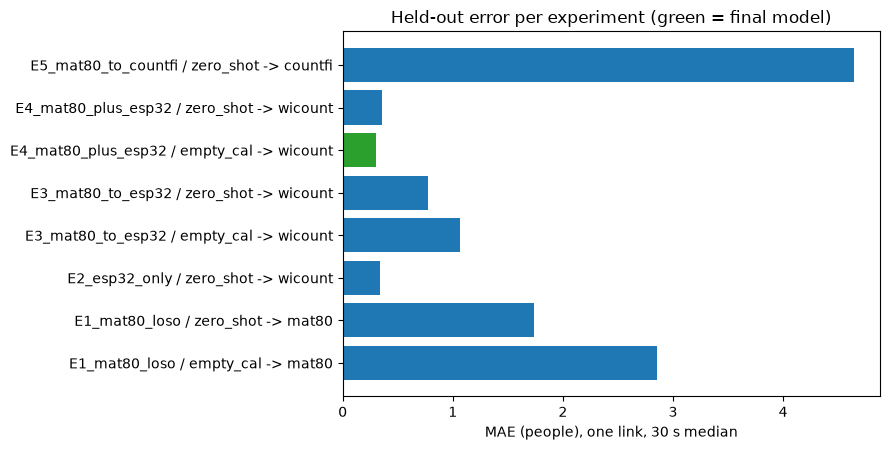

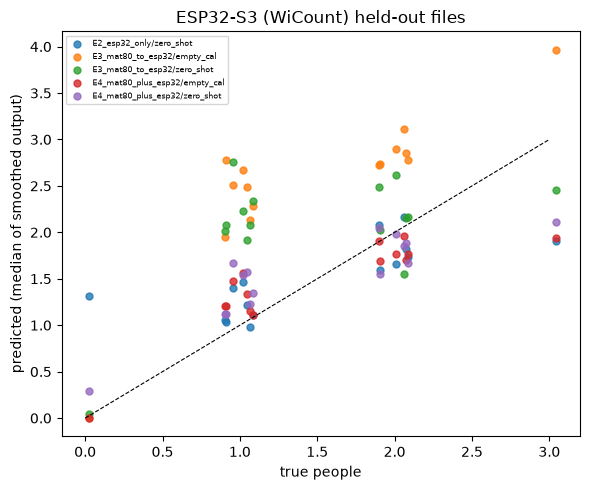

saved D:/wifi/results/phase3\PHASE3_RESULTS.md


In [10]:
# 10. Save results, figures and the Phase 3 report
results.to_csv(os.path.join(RESULTS, "results.csv"), index=False)
per_rec.to_csv(os.path.join(RESULTS, "recording_predictions.csv"), index=False)
replay.to_csv(os.path.join(RESULTS, "replay_wicount.csv"), index=False)
budget.to_csv(os.path.join(RESULTS, "esp32_budget.csv"), index=False)
rate.to_csv(os.path.join(RESULTS, "wicount_packet_rate.csv"), index=False)

fig_dir = os.path.join(RESULTS, "figures")
os.makedirs(fig_dir, exist_ok=True)

# ---- smoothed MAE per experiment ----
s = results[(results["level"] == "smoothed") & (results["sites"] == "all")].copy()
s["label"] = s["experiment"] + " / " + s["mode"] + " -> " + s["test"]
s = s.sort_values("label")
fig, ax = plt.subplots(figsize=(9, 0.45 * len(s) + 1))
colors = ["tab:green" if (e, m) == CHOSEN else "tab:blue" for e, m in zip(s["experiment"], s["mode"])]
ax.barh(s["label"], s["mae"], color=colors)
ax.set_xlabel("MAE (people), one link, 30 s median")
ax.set_title("Held-out error per experiment (green = final model)")
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, "mae_per_experiment.png"), dpi=120)
plt.show()

# ---- WiCount: whole-file estimate per candidate ----
w = per_rec[per_rec["dataset"] == "wicount"]
fig, ax = plt.subplots(figsize=(6, 5))
for (e, m), h in w.groupby(["experiment", "mode"]):
    jitter = np.random.default_rng(0).uniform(-0.1, 0.1, len(h))
    ax.scatter(h["count"] + jitter, h["pred"], s=25, label=f"{e}/{m}", alpha=0.8)
ax.plot([0, 3], [0, 3], "k--", lw=0.8)
ax.set_xlabel("true people")
ax.set_ylabel("predicted (median of smoothed output)")
ax.set_title("ESP32-S3 (WiCount) held-out files")
ax.legend(fontsize=6)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, "wicount_recordings.png"), dpi=120)
plt.show()

# ---- markdown report ----
show = ["experiment", "mode", "test", "sites", "train", "n", "mae", "exact", "within1", "spearman_rec"]
lines = [
    "# Phase 3 results - final ESP32-S3 people counter", "",
    f"Generated {time.strftime('%Y-%m-%d %H:%M')}. One link (one view), causal preprocessing, "
    f"{ec.WIN_S} s windows every {ec.HOP_S} s, output = median of the last {ec.SMOOTH_S:.0f} s.", "",
    "## Final model", "",
    f"- Chosen: **{CHOSEN[0]} / {CHOSEN[1]}** (rule: {card['selection']['rule']})",
    f"- Trained on: {', '.join(card['training_data'])} ({card['n_training_windows']} windows), "
    f"counts 0-{model.max_count}",
    f"- Calibration: {card['calibration_howto']}",
    f"- Size: {card['n_trees']} trees, {card['n_nodes']} nodes, ~{card['flash_bytes_est'] / 1024:.0f} KB flash",
    f"- Files: `{MODEL_DIR}/` (trees.json, counter_model.h, model.txt, model_card.json)", "",
    "## Held-out results (smoothed output)", "",
    table[show].round(3).to_markdown(index=False), "",
    "## Candidates on the ESP32-S3 data (WiCount)", "",
    cand.reset_index().round(3).to_markdown(index=False), "",
    "## Replay of the raw ESP32 CSVs through the saved bundle (pipeline check)", "",
    replay.to_markdown(index=False), "",
    "## ESP32-S3 budget (estimates)", "",
    budget.to_markdown(index=False), "",
    "## Caveats", "",
] + [f"- {c}" for c in card["caveats"]]

with open(os.path.join(RESULTS, "PHASE3_RESULTS.md"), "w") as f:
    f.write(chr(10).join(lines))
print("saved", os.path.join(RESULTS, "PHASE3_RESULTS.md"))

In [11]:
# 11. Done - how to use the model
print("Phase 3 finished.")
print("Model bundle :", MODEL_DIR)
print("Report       :", os.path.join(RESULTS, "PHASE3_RESULTS.md"))
print()
print("Python (demo / friend's app):")
print("    import esp32_counter as ec")
print("    model, card = ec.load_bundle(MODEL_DIR)")
print("    counter = ec.StreamingCounter(model)")
if card["calibration"] == "empty_cal":
    print("    counter.begin_calibration()        # room empty for the first 30 s")
print("    for t, amp52 in packets:             # amp52 = |CSI| of the 52 data tones")
print("        for r in counter.push(t, amp52):")
print("            if r['status'] == 'ok': print(r['count'])")
print()
print("ESP32 firmware: #include \"counter_model.h\" -> cc_prepare(raw_features, offset, x); cc_predict(x)")

Phase 3 finished.
Model bundle : D:/wifi/models/esp32_counter
Report       : D:/wifi/results/phase3\PHASE3_RESULTS.md

Python (demo / friend's app):
    import esp32_counter as ec
    model, card = ec.load_bundle(MODEL_DIR)
    counter = ec.StreamingCounter(model)
    counter.begin_calibration()        # room empty for the first 30 s
    for t, amp52 in packets:             # amp52 = |CSI| of the 52 data tones
        for r in counter.push(t, amp52):
            if r['status'] == 'ok': print(r['count'])

ESP32 firmware: #include "counter_model.h" -> cc_prepare(raw_features, offset, x); cc_predict(x)
